<a href="https://colab.research.google.com/github/NICKSTER0506/IoT-Intrusion-Detection-Deployment-Gap/blob/main/CICIDS2017__DL_IID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=5df09a2901ea8c9cca3b7b23a06d93e4a8f55957beb1d92e2e62878ac420454f
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler, LabelEncoder
import psutil
import time
import random
import math
import lime
import lime.lime_tabular

In [5]:
# till cell no 17, its about downloading the dataset in mydrive
!pip install -q kagglehub

In [6]:
import kagglehub

path = kagglehub.dataset_download(
    "chethuhn/network-intrusion-dataset"
)

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.
Dataset downloaded to: /kaggle/input/network-intrusion-dataset


In [7]:
import os

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/network-intrusion-dataset/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Tuesday-WorkingHours.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Monday-WorkingHours.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Friday-WorkingHours-Morning.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/kaggle/input/network-intrusion-dataset/Wednesday-workingHours.pcap_ISCX.csv


In [8]:
import os

for file in os.listdir(path):
    if "ddos" in file.lower():
        full_path = os.path.join(path, file)
        print(file)
        print("Size:", round(os.path.getsize(full_path) / (1024**2), 2), "MB")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Size: 73.55 MB


In [9]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

source = path
destination = '/content/drive/MyDrive/DL-IID/CICIDS2017'

os.makedirs(destination, exist_ok=True)

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Dataset copied successfully to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset copied successfully to Google Drive!


In [12]:
import os
import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass.getpass(
    "Paste your new Kaggle API token: "
)

!pip install -q --upgrade kagglehub

print("Kaggle authentication configured!")

Paste your new Kaggle API token: ··········
Kaggle authentication configured!


In [14]:
!pip install -q kagglehub

import os
import shutil
import kagglehub

BASE = "/content/drive/MyDrive/DL-IID"
os.makedirs(BASE, exist_ok=True)

# Download original UNSW-NB15
src = kagglehub.dataset_download("mrwellsdavid/unsw-nb15")

# Copy everything to Google Drive
dst = os.path.join(BASE, "UNSW_NB15")
shutil.copytree(src, dst, dirs_exist_ok=True)

print("UNSW-NB15 downloaded and copied!")
print("Location:", dst)

Using Colab cache for faster access to the 'unsw-nb15' dataset.
UNSW-NB15 downloaded and copied!
Location: /content/drive/MyDrive/DL-IID/UNSW_NB15


In [ ]:
import os

BASE = "/content/drive/MyDrive/DL-IID"

for dataset in ["CICIDS2017", "UNSW_NB15", "CICIoMT2024"]:
    folder = os.path.join(BASE, dataset)

    if os.path.exists(folder):
        files = [
            os.path.join(root, f)
            for root, _, filenames in os.walk(folder)
            for f in filenames
        ]

        size = sum(os.path.getsize(f) for f in files) / (1024**3)

        print(f"{dataset}: FOUND")
        print(f"  Files: {len(files)}")
        print(f"  Size: {size:.2f} GB")
    else:
        print(f"{dataset}: NOT FOUND")

In [17]:
# dataset = pd.read_csv('/content/drive/MyDrive/DDoS-17/DDoS.csv')
dataset = pd.read_csv(
    '/content/drive/MyDrive/DL-IID/CICIDS2017/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'
)

In [18]:
dataset.describe().

,count,mean,std,min,25%,50%,75%,max
Destination Port,225745.0,8.879619e+03,1.975465e+04,0.0,80.0,80.0,80.0,65532.0
Flow Duration,225745.0,1.624165e+07,3.152437e+07,-1.0,71180.0,1452333.0,8805237.0,119999937.0
Total Fwd Packets,225745.0,4.874916e+00,1.542287e+01,1.0,2.0,3.0,5.0,1932.0
Total Backward Packets,225745.0,4.572775e+00,2.175536e+01,0.0,1.0,4.0,5.0,2942.0
Total Length of Fwd Packets,225745.0,9.394633e+02,3.249403e+03,0.0,26.0,30.0,63.0,183012.0
...,...,...,...,...,...,...,...,...
Active Min,225745.0,1.776201e+05,7.842602e+05,0.0,0.0,0.0,1862.0,100000000.0
Idle Mean,225745.0,1.032214e+07,2.185303e+07,0.0,0.0,0.0,8239725.0,120000000.0
Idle Std,225745.0,3.611943e+06,1.275689e+07,0.0,0.0,0.0,0.0,65300000.0
Idle Max,225745.0,1.287813e+07,2.692126e+07,0.0,0.0,0.0,8253838.0,120000000.0


In [19]:
dataset.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [20]:
dataset.shape

(225745, 79)

In [21]:
dataset.isnull().sum()

,0
Destination Port,0
Flow Duration,0
Total Fwd Packets,0
Total Backward Packets,0
Total Length of Fwd Packets,0
...,...
Idle Mean,0
Idle Std,0
Idle Max,0
Idle Min,0


In [22]:
dataset.columns

Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std', 'Bwd Packet Length Max',
       ' Bwd Packet Length Min', ' Bwd Packet Length Mean',
       ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s',
       ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min',
       'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max',
       ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std',
       ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags',
       ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length',
       ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s',
       ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean',
       ' Packet Length Std', ' Packet Length Variance', '

In [23]:
dataset[' Label'].value_counts()

,count
Label,
DDoS,128027
BENIGN,97718


In [24]:
X = dataset.drop([' Label'], axis=1)
y = dataset[' Label']

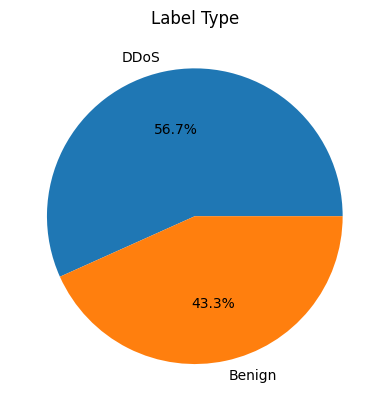

In [25]:
graph_labels = 'DDoS', 'Benign'
graph_y = y.value_counts()
fig, ax = plt.subplots()
ax.pie(graph_y, labels=graph_labels, autopct='%1.1f%%')
plt.title('Label Type')
plt.show()

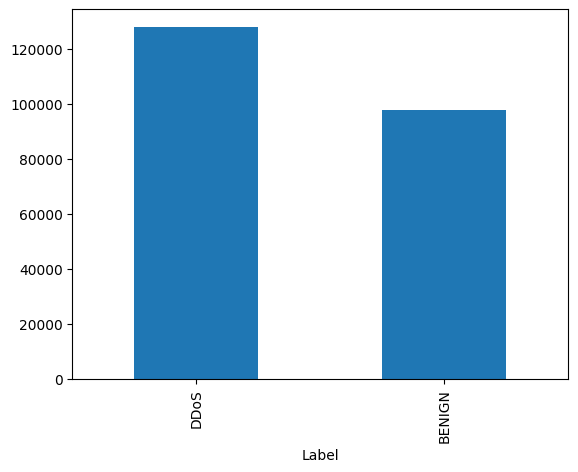

In [26]:
graph_y.plot(kind='bar', xlabel='Label')
plt.show()

In [27]:
X = X.replace([np.inf, -np.inf], np.nan)

In [28]:
encoder = LabelEncoder()

for column in X.select_dtypes(include=['object']).columns:
  X[column] = encoder.fit_transform(X[column])
y = encoder.fit_transform(y)

In [29]:
X.fillna(X.mean(), inplace=True)

In [30]:
X.shape

(225745, 78)

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [32]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [33]:
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
        assert len(self.X) == len(self.y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        y = self.y[idx]
        return x, y

In [34]:
train_dataset = MyDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = MyDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
val_dataset = MyDataset(X_val, y_val)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### DNN-BiLSTM

In [36]:
class DNNBiLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, lstm_layers, output_size):
        super(DNNBiLSTM, self).__init__()

        self.fc1 = nn.Linear(input_size, 128)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()

        self.lstm = nn.LSTM(input_size=64, hidden_size=hidden_size,
                            num_layers=lstm_layers, batch_first=True,
                            bidirectional=True)

        self.fc3 = nn.Linear(hidden_size * 2, output_size)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = x.float()
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = x.unsqueeze(1)
        lstm_out, _ = self.lstm(x)
        lstm_out = lstm_out[:, -1, :]

        x = self.fc3(lstm_out)
        return self.softmax(x)

    def predict_proba(self, x):
      with torch.no_grad():
          x = torch.tensor(x, dtype=torch.float32)
          output = self.forward(x)
          probabilities = F.softmax(output, dim=1).numpy()
          return probabilities

In [38]:
def train(model, train_loader, val_loader, criterion, optimizer, num_epochs=50):
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    for epoch in range(num_epochs):
        model.train()
        total_train_loss, correct_train, total_samples = 0, 0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_train += (predicted == labels).sum().item()
            total_samples += labels.size(0)

        train_loss = total_train_loss / len(train_loader)
        train_accuracy = (correct_train / total_samples) * 100

        # Validation Phase
        model.eval()
        total_val_loss, correct_val, total_val_samples = 0, 0, 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                total_val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                correct_val += (predicted == labels).sum().item()
                total_val_samples += labels.size(0)

        val_loss = total_val_loss / len(val_loader)
        val_accuracy = (correct_val / total_val_samples) * 100

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Train Acc: {train_accuracy:.2f}% | Val Acc: {val_accuracy:.2f}%")

    return train_losses, val_losses, train_accuracies, val_accuracies

In [39]:
def plot_performance(train_losses, val_losses, train_acc, val_acc):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Loss Plot
    axes[0].plot(train_losses, label="Train Loss", color='blue')
    axes[0].plot(val_losses, label="Validation Loss", color='red')
    axes[0].set_title("Loss Curve")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # Accuracy Plot
    axes[1].plot(train_acc, label="Train Accuracy", color='blue')
    axes[1].plot(val_acc, label="Validation Accuracy", color='red')
    axes[1].set_title("Accuracy Curve")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()

    plt.show()

In [40]:
input_size = X_train.shape[1]
hidden_size = 64
lstm_layers = 1
output_size = 2
batch_size = 128
num_epochs = 20
learning_rate = 0.0001

In [41]:
model = DNNBiLSTM(input_size, hidden_size, lstm_layers, output_size).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [42]:
train_losses, val_losses, train_acc, val_acc = train(model, train_loader, val_loader, criterion, optimizer, num_epochs)

Epoch 1/20 | Train Loss: 0.3441 | Val Loss: 0.3147 | Train Acc: 98.04% | Val Acc: 99.88%
Epoch 2/20 | Train Loss: 0.3148 | Val Loss: 0.3142 | Train Acc: 99.86% | Val Acc: 99.92%
Epoch 3/20 | Train Loss: 0.3146 | Val Loss: 0.3141 | Train Acc: 99.86% | Val Acc: 99.92%
Epoch 4/20 | Train Loss: 0.3146 | Val Loss: 0.3140 | Train Acc: 99.87% | Val Acc: 99.92%
Epoch 5/20 | Train Loss: 0.3145 | Val Loss: 0.3145 | Train Acc: 99.87% | Val Acc: 99.87%
Epoch 6/20 | Train Loss: 0.3145 | Val Loss: 0.3140 | Train Acc: 99.87% | Val Acc: 99.92%
Epoch 7/20 | Train Loss: 0.3145 | Val Loss: 0.3140 | Train Acc: 99.87% | Val Acc: 99.92%
Epoch 8/20 | Train Loss: 0.3146 | Val Loss: 0.3140 | Train Acc: 99.87% | Val Acc: 99.92%
Epoch 9/20 | Train Loss: 0.3145 | Val Loss: 0.3140 | Train Acc: 99.87% | Val Acc: 99.92%
Epoch 10/20 | Train Loss: 0.3145 | Val Loss: 0.3142 | Train Acc: 99.87% | Val Acc: 99.89%
Epoch 11/20 | Train Loss: 0.3145 | Val Loss: 0.3140 | Train Acc: 99.87% | Val Acc: 99.92%
Epoch 12/20 | Train

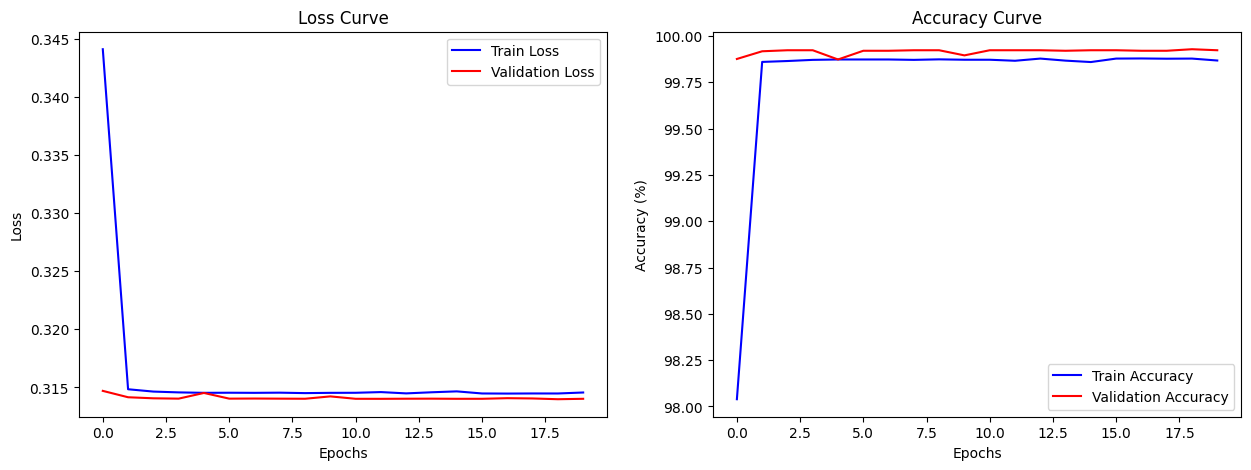

In [43]:
plot_performance(train_losses, val_losses, train_acc, val_acc)

In [44]:
def evaluate_model(model, test_loader):
    model.eval()
    test_loss = 0
    correct = 0
    predictions = []
    labels = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device, dtype=torch.float32), y.to(device, dtype=torch.long)
            outputs = model(x)
            loss = criterion(outputs, y)
            test_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y).sum().item()

            predictions.extend(predicted.cpu().numpy())
            labels.extend(y.cpu().numpy())

    # Convert to numpy arrays
    labels_array = np.array(labels)
    predictions_array = np.array(predictions)

    # Compute evaluation metrics
    accuracy = correct / len(test_loader.dataset)
    precision = precision_score(labels, predictions, zero_division=False)
    recall = recall_score(labels, predictions, zero_division=False)
    f1 = f1_score(labels, predictions, zero_division=False)

    # Compute error metrics
    MSE = mean_squared_error(labels_array, predictions_array)
    RMSE = np.sqrt(MSE)
    MAE = mean_absolute_error(labels_array, predictions_array)

    safe_labels = np.where(labels_array == 0, np.nan, labels_array)
    MAPE = np.nanmean(np.abs((labels_array - predictions_array) / safe_labels)) * 100

    # System Resource Utilization
    process = psutil.Process()
    cpu_utilization = psutil.cpu_percent(interval=1)
    memory_usage = process.memory_info().rss / 1024  # Convert to KB

    # Print Results
    print("\n--- Evaluation Metrics ---")
    print(f"Test Loss: {test_loss / len(test_loader):.4f}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

    print("\n--- Error Metrics ---")
    print(f"Mean Absolute Error (MAE): {MAE:.4f}")
    print(f"Mean Squared Error (MSE): {MSE:.4f}")
    print(f"Root Mean Squared Error (RMSE): {RMSE:.4f}")
    print(f"Mean Absolute Percentage Error (MAPE): {MAPE:.2f}%")

    print("\n--- System Resource Utilization ---")
    print(f"CPU Utilization: {cpu_utilization}%")
    print(f"Memory Usage: {memory_usage:.2f} KB")

    # Print Classification Report
    print("\n--- Classification Report ---")
    print(classification_report(labels, predictions, target_names=['Benign', 'DDoS']))

    # Plot Confusion Matrix
    conf_matrix = confusion_matrix(labels, predictions)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=['Benign', 'DDoS'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.show()


--- Evaluation Metrics ---
Test Loss: 0.3143
Test Accuracy: 0.9990
Precision: 0.9999
Recall: 0.9983
F1 Score: 0.9991

--- Error Metrics ---
Mean Absolute Error (MAE): 0.0010
Mean Squared Error (MSE): 0.0010
Root Mean Squared Error (RMSE): 0.0323
Mean Absolute Percentage Error (MAPE): 0.17%

--- System Resource Utilization ---
CPU Utilization: 28.3%
Memory Usage: 1113664.00 KB

--- Classification Report ---
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     19405
        DDoS       1.00      1.00      1.00     25744

    accuracy                           1.00     45149
   macro avg       1.00      1.00      1.00     45149
weighted avg       1.00      1.00      1.00     45149



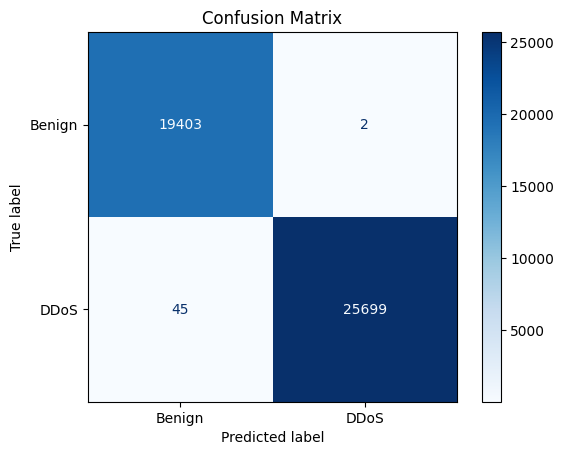

In [45]:
evaluate_model(model, test_loader)

###Fitness (Objective) Function

In [46]:
def train_on_selected_features(selected_features, X, y, epochs=50, batch_size=128):
    selected_features_indices = np.where(selected_features)[0]
    X_selected = X.iloc[:, selected_features_indices]

    scaler = StandardScaler()
    X_selected = scaler.fit_transform(X_selected)

    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

    train_dataset1 = MyDataset(X_train, y_train)
    train_loader1 = DataLoader(train_dataset1, batch_size=64, shuffle=True)
    val_dataset1 = MyDataset(X_val, y_val)
    val_loader1 = DataLoader(val_dataset1, batch_size=64, shuffle=False)

    input_size = X_train.shape[1]
    hidden_size = 64
    lstm_layers = 1
    output_size = 2
    model = DNNBiLSTM(input_size, hidden_size, lstm_layers, output_size).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for batch in train_loader1:
            x, y = batch
            y = y.long()
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0

        with torch.no_grad():
            for batch in val_loader1:
                x, y = batch
                y = y.long()
                outputs = model(x)
                loss = criterion(outputs, y)
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == y).sum().item()

        accuracy = correct / len(val_dataset1)

        return 1 - accuracy

In [47]:
class solution:
    def __init__(self):
        self.best = 0
        self.bestIndividual = []
        self.convergence = []
        self.optimizer = ""
        self.objfname = ""
        self.startTime = 0
        self.endTime = 0
        self.executionTime = 0
        self.lb = 0
        self.ub = 0
        self.dim = 0
        self.popnum = 0
        self.maxiers = 0

### GA

In [48]:
def crossover(individualLength, parent1, parent2):
    crossover_point = random.randint(1, individualLength - 1)
    offspring1 = np.concatenate([parent1[:crossover_point], parent2[crossover_point:]])
    offspring2 = np.concatenate([parent2[:crossover_point], parent1[crossover_point:]])
    return offspring1, offspring2

In [49]:
def mutation(individual, individualLength, lb, ub):
    mutationIndex = random.randint(0, individualLength - 1)
    individual[mutationIndex] = 1 - individual[mutationIndex]

In [50]:
def pairSelection(population, scores, popSize):
    def rouletteWheelSelectionId(scores, popSize):
        total_fitness = sum(scores)
        normalized_scores = [score / total_fitness for score in scores]
        cumulative_probs = np.cumsum(normalized_scores)
        random_num = random.random()
        for i, cumulative_prob in enumerate(cumulative_probs):
            if random_num <= cumulative_prob:
                return i

    parent1Id = rouletteWheelSelectionId(scores, popSize)
    parent1 = population[parent1Id].copy()

    parent2Id = parent1Id
    while parent2Id == parent1Id:
        parent2Id = rouletteWheelSelectionId(scores, popSize)

    parent2 = population[parent2Id].copy()

    return parent1, parent2

In [51]:
def mutatePopulaton(population, popSize, mutationProbability, keep, lb, ub):
    for i in range(keep, popSize):
        if random.random() < mutationProbability:
            mutation(population[i], len(population[i]), lb, ub)

In [52]:
def sortPopulation(population, scores):
    sorted_indices = scores.argsort()
    population = population[sorted_indices]
    scores = scores[sorted_indices]
    return population, scores

In [53]:
def crossoverPopulaton(population, scores, popSize, crossoverProbability, keep):
    newPopulation = np.zeros_like(population)
    newPopulation[:keep] = population[:keep]

    for i in range(keep, popSize, 2):
        parent1, parent2 = pairSelection(population, scores, popSize)
        individualLength = len(parent1)

        if random.random() < crossoverProbability:
            offspring1, offspring2 = crossover(individualLength, parent1, parent2)
        else:
            offspring1, offspring2 = parent1.copy(), parent2.copy()

        newPopulation[i] = offspring1
        if i + 1 < popSize:
            newPopulation[i + 1] = offspring2

    return newPopulation

In [54]:
def clearDups(population, lb, ub):
    unique_population = np.unique(population, axis=0)
    num_duplicates = len(population) - len(unique_population)

    if num_duplicates > 0:
        random_individuals = np.random.randint(2, size=(num_duplicates, population.shape[1]))
        unique_population = np.vstack((unique_population, random_individuals))

    return unique_population

In [55]:
def GA(objf, lb, ub, dim, popSize, iters):
    cp = 0.8
    mp = 0.05
    keep = 2
    s = solution()

    bestScore = float("inf")
    bestIndividual = None

    ga = np.random.randint(2, size=(popSize, dim))
    convergence_curve = np.zeros(iters)

    print('GA is optimizing "' + objf.__name__ + '" for feature selection')

    timerStart = time.time()
    s.startTime = time.strftime("%Y-%m-%d-%H-%M-%S")

    for l in range(iters):
        scores = np.array([objf(ind) for ind in ga])

        ga, scores = sortPopulation(ga, scores)

        if scores[0] < bestScore:
            bestScore = scores[0]
            bestIndividual = ga[0]

        convergence_curve[l] = bestScore

        if l % 1 == 0:
            print(f"Iteration {l + 1}, best fitness (error): {bestScore:.4f}")

        ga = crossoverPopulaton(ga, scores, popSize, cp, keep)
        mutatePopulaton(ga, popSize, mp, keep, lb, ub)
        ga = clearDups(ga, lb, ub)

    timerEnd = time.time()
    s.bestIndividual = bestIndividual
    s.bestScore = bestScore
    s.executionTime = timerEnd - timerStart
    s.convergence = convergence_curve
    s.optimizer = "GA"
    s.objfname = objf.__name__

    return s

In [56]:
dim = X.shape[1]
lb = [0] * dim
ub = [1] * dim
popSize = 20
iters = 5

In [57]:
def objective(selected_features):
  return train_on_selected_features(selected_features, X, y)

In [58]:
best_solution = GA(objective, lb, ub, dim, popSize, iters)

print(f"Best feature set: {best_solution.bestIndividual}")
print(f"Best accuracy (1 - best error): {1 - best_solution.bestScore}")

GA is optimizing "objective" for feature selection
Iteration 1, best fitness (error): 0.0008
Iteration 2, best fitness (error): 0.0008
Iteration 3, best fitness (error): 0.0008
Iteration 4, best fitness (error): 0.0008
Iteration 5, best fitness (error): 0.0008
Best feature set: [1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1 1 1 1 1 0 1 0 1 0 0 0 1 1 0 1 1
 0 0 1 1 1 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 1 0 0 1 0 1 0 0 1 1 0 1 0
 1 1 1 0]
Best accuracy (1 - best error): 0.9991694352159468


In [59]:
selected_features_ga = best_solution.bestIndividual

In [60]:
selected_features_ga

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0])

In [61]:
selected_features_ga_original = [X.columns[i] for i, x in enumerate(selected_features_ga) if x == 1]
print(selected_features_ga_original)
print(len(selected_features_ga_original))

[' Destination Port', ' Fwd Packet Length Min', ' Flow Packets/s', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', ' Bwd IAT Mean', ' Bwd IAT Max', ' Fwd URG Flags', ' Bwd URG Flags', ' Bwd Header Length', 'Fwd Packets/s', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' ECE Flag Count', ' Avg Bwd Segment Size', ' Fwd Header Length.1', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', 'Bwd Avg Bulk Rate', ' Subflow Bwd Packets', 'Init_Win_bytes_forward', ' min_seg_size_forward', 'Active Mean', ' Active Max', 'Idle Mean', ' Idle Std', ' Idle Max']
37


In [62]:
weights_ga = [1 if x in selected_features_ga_original else 0 for x in X.columns]
print(weights_ga)

[1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0]


In [63]:
selected_features_ga_original

[' Destination Port',
 ' Fwd Packet Length Min',
 ' Flow Packets/s',
 'Fwd IAT Total',
 ' Fwd IAT Mean',
 ' Fwd IAT Std',
 ' Fwd IAT Max',
 ' Fwd IAT Min',
 ' Bwd IAT Mean',
 ' Bwd IAT Max',
 ' Fwd URG Flags',
 ' Bwd URG Flags',
 ' Bwd Header Length',
 'Fwd Packets/s',
 ' Max Packet Length',
 ' Packet Length Mean',
 ' Packet Length Std',
 ' Packet Length Variance',
 'FIN Flag Count',
 ' SYN Flag Count',
 ' PSH Flag Count',
 ' ACK Flag Count',
 ' ECE Flag Count',
 ' Avg Bwd Segment Size',
 ' Fwd Header Length.1',
 'Fwd Avg Bytes/Bulk',
 ' Fwd Avg Bulk Rate',
 ' Bwd Avg Bytes/Bulk',
 'Bwd Avg Bulk Rate',
 ' Subflow Bwd Packets',
 'Init_Win_bytes_forward',
 ' min_seg_size_forward',
 'Active Mean',
 ' Active Max',
 'Idle Mean',
 ' Idle Std',
 ' Idle Max']

### GA Features

In [64]:
ga_features_indices = [X.columns.get_loc(col) for col in selected_features_ga_original]

In [65]:
X_selected_ga = X.iloc[:, ga_features_indices]

In [66]:
X_train_selected_ga, X_test_selected_ga, y_train_selected_ga, y_test_selected_ga = train_test_split(X_selected_ga, y, test_size=0.3, random_state=42)
X_train_selected_ga, X_val_selected_ga, y_train_selected_ga, y_val_selected_ga = train_test_split(X_train_selected_ga, y_train_selected_ga, test_size=0.2, random_state=42)

In [67]:
X_train_selected_ga = scaler.fit_transform(X_train_selected_ga)
X_test_selected_ga = scaler.transform(X_test_selected_ga)
X_val_selected_ga = scaler.transform(X_val_selected_ga)

In [68]:
train_dataset_selected_ga = MyDataset(X_train_selected_ga, y_train_selected_ga)
train_loader_selected_ga = DataLoader(train_dataset_selected_ga, batch_size=64, shuffle=True)
test_dataset_selected_ga = MyDataset(X_test_selected_ga, y_test_selected_ga)
test_loader_selected_ga = DataLoader(test_dataset_selected_ga, batch_size=64, shuffle=False)
val_dataset_selected_ga = MyDataset(X_val_selected_ga, y_val_selected_ga)
val_loader_selected_ga = DataLoader(val_dataset_selected_ga, batch_size=64, shuffle=False)

In [69]:
model_selected_ga = DNNBiLSTM(input_size=X_train_selected_ga.shape[1], hidden_size=64, lstm_layers=1, output_size=2)
criterion = nn.CrossEntropyLoss()
optimizer_selected_ga = optim.Adam(model_selected_ga.parameters(), lr=0.0001)

In [70]:
train_losses_selected_ga, val_losses_selected_ga, train_acc_selected_ga, val_acc_selected_ga = train(model_selected_ga, train_loader_selected_ga, val_loader_selected_ga, criterion, optimizer_selected_ga, num_epochs)

Epoch 1/20 | Train Loss: 0.3563 | Val Loss: 0.3172 | Train Acc: 97.31% | Val Acc: 99.53%
Epoch 2/20 | Train Loss: 0.3156 | Val Loss: 0.3150 | Train Acc: 99.87% | Val Acc: 99.86%
Epoch 3/20 | Train Loss: 0.3147 | Val Loss: 0.3146 | Train Acc: 99.89% | Val Acc: 99.88%
Epoch 4/20 | Train Loss: 0.3145 | Val Loss: 0.3145 | Train Acc: 99.89% | Val Acc: 99.88%
Epoch 5/20 | Train Loss: 0.3143 | Val Loss: 0.3144 | Train Acc: 99.90% | Val Acc: 99.89%
Epoch 6/20 | Train Loss: 0.3143 | Val Loss: 0.3144 | Train Acc: 99.90% | Val Acc: 99.89%
Epoch 7/20 | Train Loss: 0.3143 | Val Loss: 0.3146 | Train Acc: 99.90% | Val Acc: 99.86%
Epoch 8/20 | Train Loss: 0.3142 | Val Loss: 0.3144 | Train Acc: 99.90% | Val Acc: 99.88%
Epoch 9/20 | Train Loss: 0.3143 | Val Loss: 0.3145 | Train Acc: 99.90% | Val Acc: 99.89%
Epoch 10/20 | Train Loss: 0.3142 | Val Loss: 0.3146 | Train Acc: 99.90% | Val Acc: 99.86%
Epoch 11/20 | Train Loss: 0.3142 | Val Loss: 0.3144 | Train Acc: 99.91% | Val Acc: 99.89%
Epoch 12/20 | Train

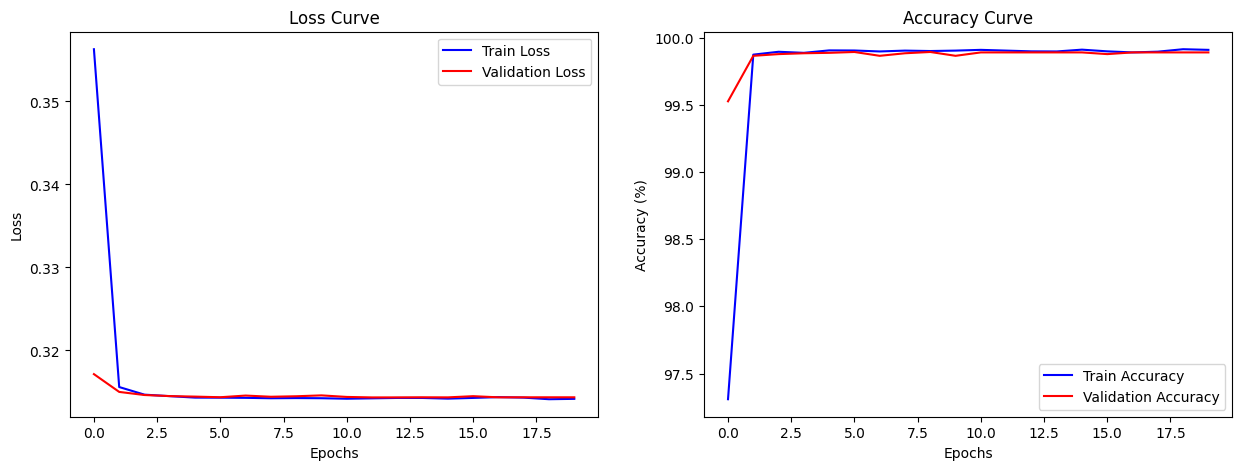

In [71]:
plot_performance(train_losses_selected_ga, val_losses_selected_ga, train_acc_selected_ga, val_acc_selected_ga)


--- Evaluation Metrics ---
Test Loss: 0.3142
Test Accuracy: 0.9990
Precision: 0.9997
Recall: 0.9986
F1 Score: 0.9991

--- Error Metrics ---
Mean Absolute Error (MAE): 0.0010
Mean Squared Error (MSE): 0.0010
Root Mean Squared Error (RMSE): 0.0312
Mean Absolute Percentage Error (MAPE): 0.14%

--- System Resource Utilization ---
CPU Utilization: 57.4%
Memory Usage: 1278948.00 KB

--- Classification Report ---
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     29262
        DDoS       1.00      1.00      1.00     38462

    accuracy                           1.00     67724
   macro avg       1.00      1.00      1.00     67724
weighted avg       1.00      1.00      1.00     67724



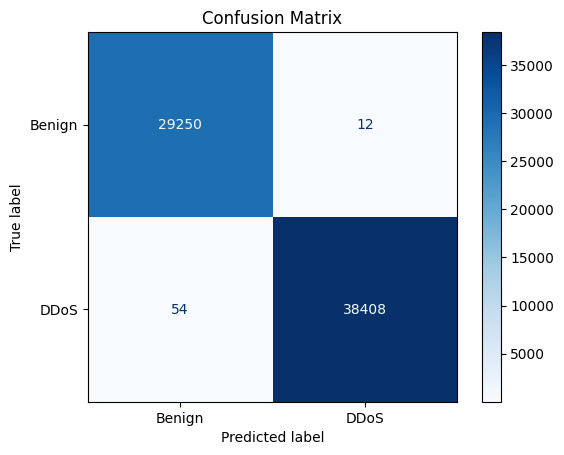

In [72]:
evaluate_model(model_selected_ga, test_loader_selected_ga)

### LIME for DNN-BiLSTM with All Features

In [73]:
explainer1 = lime.lime_tabular.LimeTabularExplainer(X_train,
                                                   feature_names=X.columns.tolist(),
                                                   mode='classification',
                                                   discretize_continuous=True)

In [74]:
i = 10
exp1 = explainer1.explain_instance(
    data_row=X_test[i],
    predict_fn=model.predict_proba,
    num_features=X_train.shape[1]
)

In [75]:
y_test_selected_ga[i]

np.int64(1)

In [76]:
exp1.show_in_notebook(show_table=True, show_predicted_value=True)

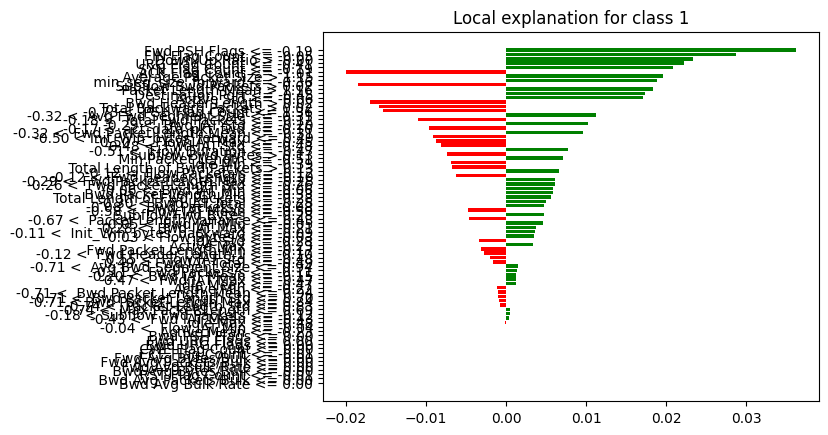

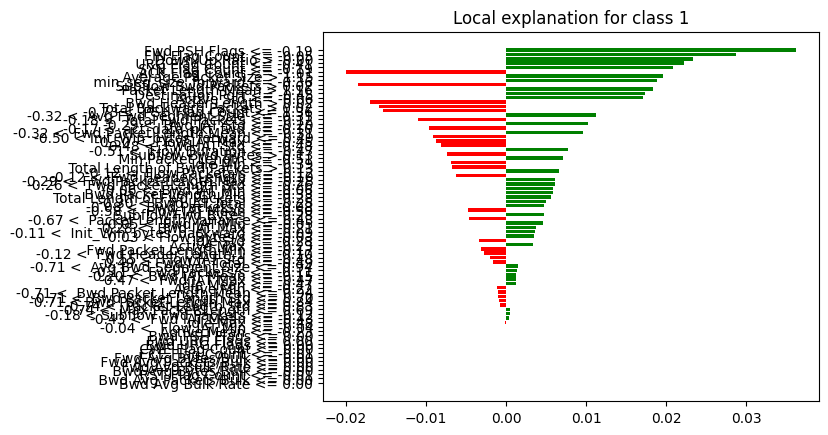

In [77]:
exp1.as_pyplot_figure()

In [78]:
feature_contributions1 = exp1.as_map()[1]
print("Feature Contributions (index-based):", feature_contributions1)

Feature Contributions (index-based): [(np.int64(30), np.float64(0.03623895944645434)), (np.int64(43), np.float64(0.02868249386573235)), (np.int64(51), np.float64(0.02337618135542443)), (np.int64(48), np.float64(0.022155424463321798)), (np.int64(44), np.float64(0.020878419216175104)), (np.int64(47), np.float64(-0.02007484294959098)), (np.int64(52), np.float64(0.019588070825288316)), (np.int64(69), np.float64(0.018782093141344772)), (np.int64(64), np.float64(-0.018554601030697355)), (np.int64(40), np.float64(0.018343261397387067)), (np.int64(0), np.float64(0.017317998290423596)), (np.int64(71), np.float64(0.017064322653940055)), (np.int64(35), np.float64(-0.01697809322886031)), (np.int64(3), np.float64(-0.01588063455791932)), (np.int64(46), np.float64(-0.015407540965913203)), (np.int64(53), np.float64(0.01121620530772939)), (np.int64(2), np.float64(-0.011079959621156139)), (np.int64(27), np.float64(0.01015109296006801)), (np.int64(68), np.float64(-0.009649396875709072)), (np.int64(8), np

### LIME for DNN-BiLSTM with GA Features

In [79]:
explainer2 = lime.lime_tabular.LimeTabularExplainer(X_train_selected_ga,
                                                   feature_names=X_selected_ga,
                                                   mode='classification',
                                                   discretize_continuous=True)

In [80]:
j=10
exp2 = explainer2.explain_instance(
    data_row=X_test_selected_ga[j],
    predict_fn=model_selected_ga.predict_proba,
    num_features=X_train_selected_ga.shape[1]
)

In [81]:
exp2.show_in_notebook(show_table=True, show_predicted_value=True)

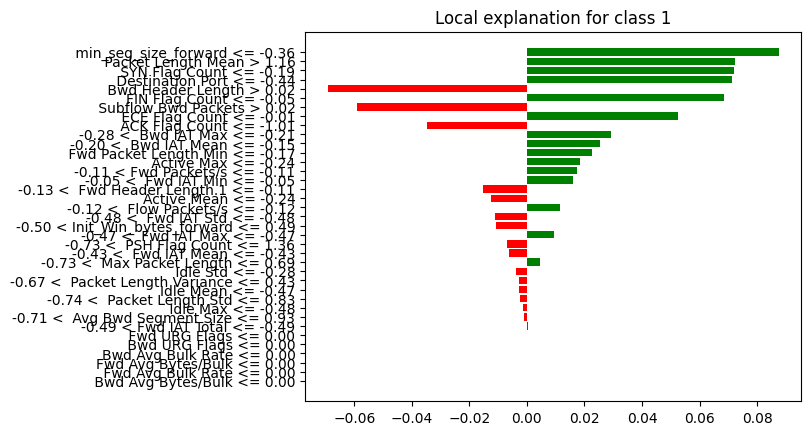

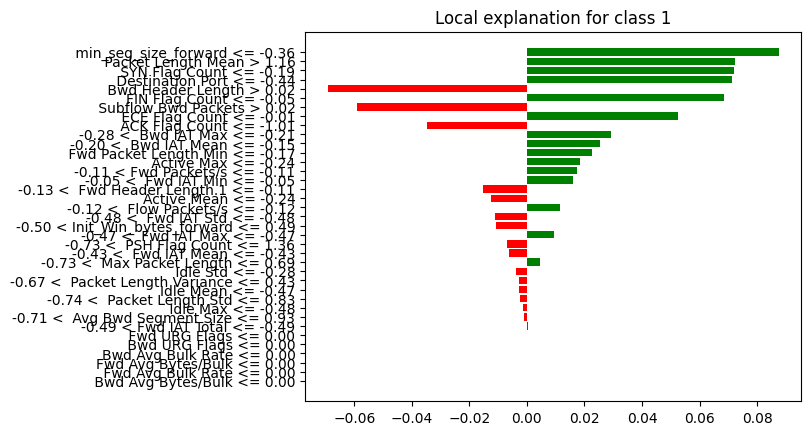

In [82]:
exp2.as_pyplot_figure()

In [83]:
feature_contributions2 = exp2.as_map()[1]
print("Feature Contributions (index-based):", feature_contributions2)

Feature Contributions (index-based): [(np.int64(31), np.float64(0.08746451033115675)), (np.int64(15), np.float64(0.07224468891007452)), (np.int64(19), np.float64(0.07202079684664944)), (np.int64(0), np.float64(0.071454146720325)), (np.int64(12), np.float64(-0.06927656284115938)), (np.int64(18), np.float64(0.06851237237521329)), (np.int64(29), np.float64(-0.05899193874322277)), (np.int64(22), np.float64(0.0525025998535404)), (np.int64(21), np.float64(-0.034638276156119446)), (np.int64(9), np.float64(0.029286418172189195)), (np.int64(8), np.float64(0.02529997646527915)), (np.int64(1), np.float64(0.022463562367304908)), (np.int64(33), np.float64(0.018577911002633774)), (np.int64(13), np.float64(0.017364724890367902)), (np.int64(7), np.float64(0.01612784076221564)), (np.int64(24), np.float64(-0.015265964774855149)), (np.int64(32), np.float64(-0.012362377715480427)), (np.int64(2), np.float64(0.01153708696404837)), (np.int64(5), np.float64(-0.010949257607047812)), (np.int64(30), np.float64(-

Model Size

In [85]:
# below code saves model in /content/drive/MyDrive/research_paper/cicids_model.pth but research_paper folder does not exist
import os

os.makedirs('/content/drive/MyDrive/research_paper', exist_ok=True)

torch.save(
    model.state_dict(),
    '/content/drive/MyDrive/research_paper/cicids_model.pth'
)

model_size = os.path.getsize(
    '/content/drive/MyDrive/research_paper/cicids_model.pth'
) / 1024

print(f"Model Size: {model_size:.2f} KB")

Model Size: 337.97 KB


In [84]:
torch.save(model.state_dict(), '/content/drive/MyDrive/research_paper/cicids_model.pth')

model_size1 = os.path.getsize('/content/drive/MyDrive/research_paper/cicids_model.pth') / 1024
print(f"Model Size: {model_size1:.2f} KB")

RuntimeError: Parent directory /content/drive/MyDrive/research_paper does not exist.

In [86]:
torch.save(model_selected_ga.state_dict(), '/content/drive/MyDrive/research_paper/cicids_ga_model.pth')

model_size_ga = os.path.getsize('/content/drive/MyDrive/research_paper/cicids_ga_model.pth') / 1024
print(f"Model Size: {model_size_ga:.2f} KB")

Model Size: 317.52 KB


### Dynamic Quantization model

In [87]:
import torch.quantization
quantized_model_ga = torch.quantization.quantize_dynamic(
    model_selected_ga,
    {nn.LSTM},
    dtype=torch.qint8
)

/tmp/ipykernel_856/723413438.py:2: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model_ga = torch.quantization.quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype


--- Evaluation Metrics ---
Test Loss: 0.3143
Test Accuracy: 0.9990
Precision: 0.9997
Recall: 0.9985
F1 Score: 0.9991

--- Error Metrics ---
Mean Absolute Error (MAE): 0.0010
Mean Squared Error (MSE): 0.0010
Root Mean Squared Error (RMSE): 0.0321
Mean Absolute Percentage Error (MAPE): 0.15%

--- System Resource Utilization ---
CPU Utilization: 3.0%
Memory Usage: 1286048.00 KB

--- Classification Report ---
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     29262
        DDoS       1.00      1.00      1.00     38462

    accuracy                           1.00     67724
   macro avg       1.00      1.00      1.00     67724
weighted avg       1.00      1.00      1.00     67724



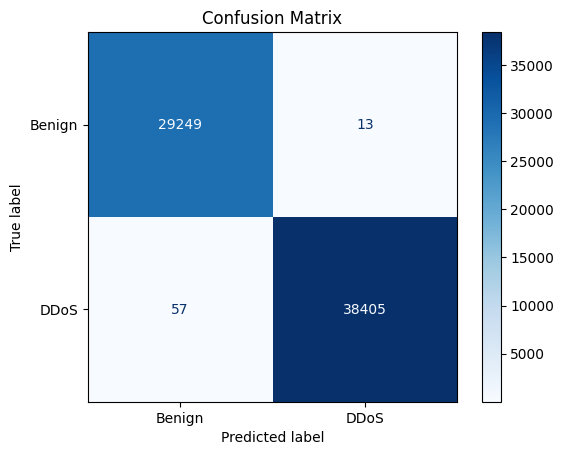

In [88]:
evaluate_model(quantized_model_ga, test_loader_selected_ga)

In [89]:
torch.save(quantized_model_ga.state_dict(), '/content/drive/MyDrive/research_paper/cicids_ga_quantised_model.pth')

quantized_ga_size = os.path.getsize('/content/drive/MyDrive/research_paper/cicids_ga_quantised_model.pth') / 1024
print(f"Model Size: {quantized_ga_size:.2f} KB")

Model Size: 126.53 KB
